<xarray.Dataset> Size: 81kB
Dimensions:     (valid_time: 922, latitude: 2, longitude: 2)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2026-10-01
    expver      (valid_time) <U4 15kB ...
  * latitude    (latitude) float64 16B 40.1 40.0
  * longitude   (longitude) float64 16B -3.1 -3.0
    number      int64 8B ...
Data variables:
    swvl1       (valid_time, latitude, longitude) float32 15kB ...
    swvl2       (valid_time, latitude, longitude) float32 15kB ...
    swvl3       (valid_time, latitude, longitude) float32 15kB ...
    swvl4       (valid_time, latitude, longitude) float32 15kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-18T10:16 GRIB to CDM+CF via cfgrib-0.9.1...


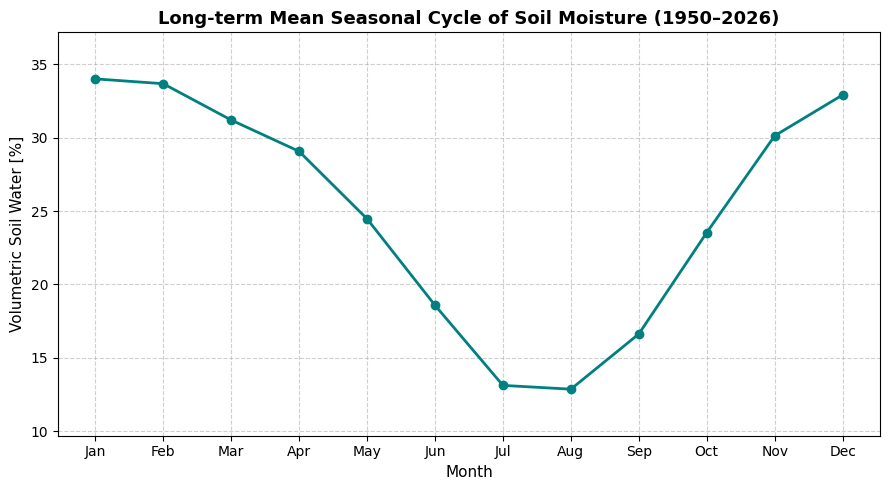

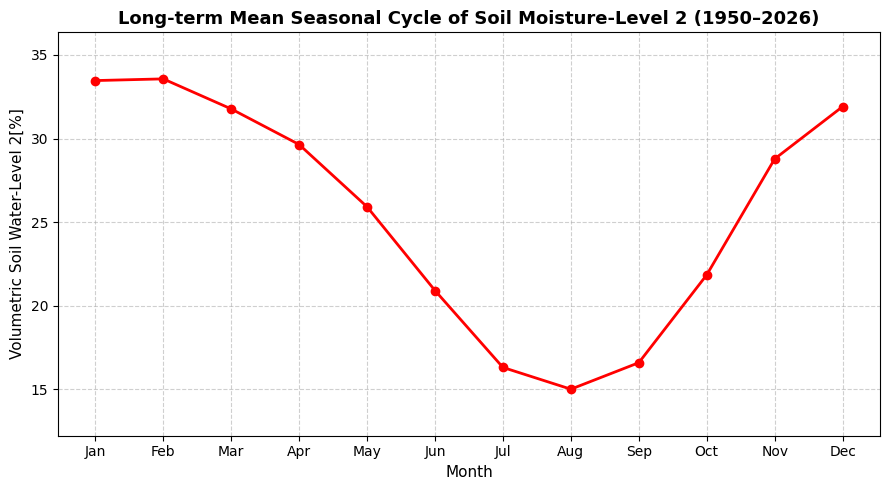

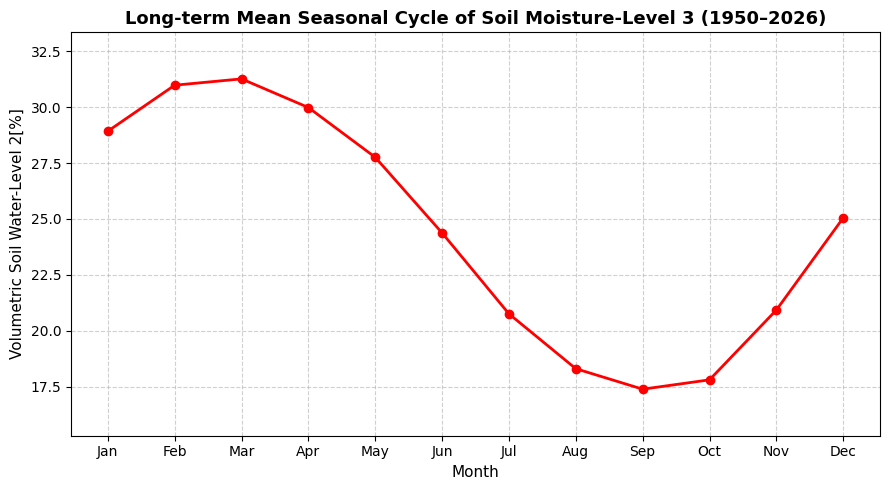

In [2]:
import os
import xarray as xr
import matplotlib.pyplot as plt

folder = r'C:\MAT3300'
file_path = os.path.join(folder, 'finalsoildataset.nc') 
ds = xr.open_dataset(file_path)
print(ds)

monthly = (
    ds["swvl1"]
    .mean(dim=["latitude", "longitude"], skipna=True)   
    .resample(valid_time="1MS")                        
    .mean()
)
monthly_pct = monthly * 100
monthly_clim = monthly_pct.groupby("valid_time.month").mean()
 
fig, ax = plt.subplots(figsize=(9, 5))
monthly_clim.plot(ax=ax, marker="o", color="teal", linewidth=2, markersize=6)

ax.set_xticks(range(1, 13))
ymin = min(monthly_clim.min().item(), monthly_clim.min().item())
ymax = max(monthly_clim.max().item(), monthly_clim.max().item())
buffer = (ymax - ymin) * 0.15  # 15% padding above and below
ax.set_ylim(ymin - buffer, ymax + buffer)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Volumetric Soil Water [%]", fontsize=11)
ax.set_title("Long-term Mean Seasonal Cycle of Soil Moisture (1950–2026)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

monthly = (
    ds["swvl2"]
    .mean(dim=["latitude", "longitude"], skipna=True)   # spatial mean only
    .resample(valid_time="1MS")                         # monthly means
    .mean()
)
monthly_pct = monthly * 100
monthly_clim = monthly_pct.groupby("valid_time.month").mean()

fig, ax = plt.subplots(figsize=(9, 5))
monthly_clim.plot(ax=ax, marker="o", color="red", linewidth=2, markersize=6)

ax.set_xticks(range(1, 13))
ymin = min(monthly_clim.min().item(), monthly_clim.min().item())
ymax = max(monthly_clim.max().item(), monthly_clim.max().item())
buffer = (ymax - ymin) * 0.15 
ax.set_ylim(ymin - buffer, ymax + buffer)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Volumetric Soil Water-Level 2[%]", fontsize=11)
ax.set_title("Long-term Mean Seasonal Cycle of Soil Moisture-Level 2 (1950–2026)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

monthly = (
    ds["swvl3"]
    .mean(dim=["latitude", "longitude"], skipna=True)   # spatial mean only
    .resample(valid_time="1MS")                         # monthly means
    .mean()
)
monthly_pct = monthly * 100
monthly_clim = monthly_pct.groupby("valid_time.month").mean()

fig, ax = plt.subplots(figsize=(9, 5))
monthly_clim.plot(ax=ax, marker="o", color="red", linewidth=2, markersize=6)

ax.set_xticks(range(1, 13))
ymin = min(monthly_clim.min().item(), monthly_clim.min().item())
ymax = max(monthly_clim.max().item(), monthly_clim.max().item())
buffer = (ymax - ymin) * 0.15 
ax.set_ylim(ymin - buffer, ymax + buffer)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Volumetric Soil Water-Level 2[%]", fontsize=11)
ax.set_title("Long-term Mean Seasonal Cycle of Soil Moisture-Level 3 (1950–2026)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

--- Pure AR(1) Stochastic Soil Model Results ---
Soil Memory Coefficient (phi): 0.8533
Model R-squared (R²): 0.7284
Noise/Shock Standard Deviation: 2.1934


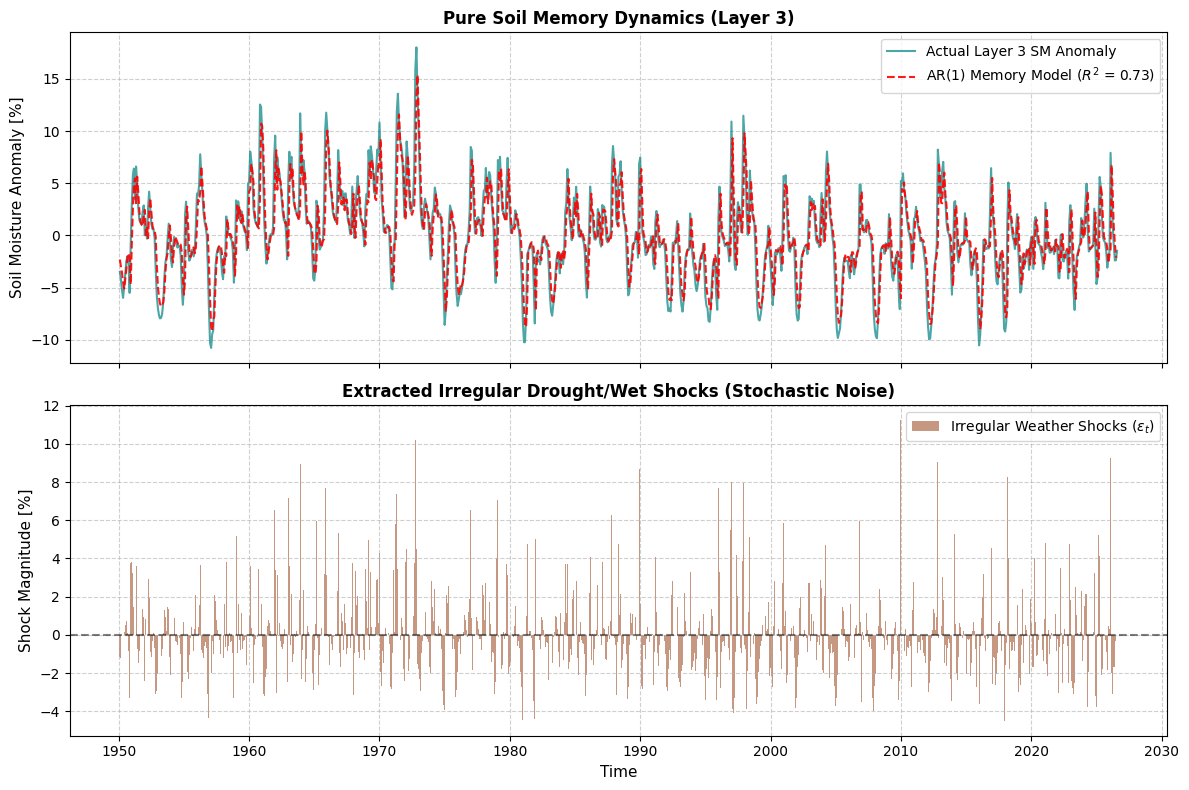

In [7]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

folder = r'C:\MAT3300'
sm_file = os.path.join(folder, 'finalsoildataset.nc') 

ds_sm = xr.open_dataset(sm_file)

sm_time_series = (
    ds_sm["swvl3"]
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
    * 100  # convert to %
)

df = pd.DataFrame({
    'SM': sm_time_series.values
}, index=sm_time_series.valid_time.values).dropna()

df['month'] = df.index.month
df['SM_anomaly'] = df.groupby('month')['SM'].transform(lambda x: x - x.mean())

df['SM_lag1'] = df['SM_anomaly'].shift(1)
df_model = df.dropna().copy()

# Fit Pure AR(1) Model: SM_t = phi * SM_{t-1} + epsilon_t
X = df_model[['SM_lag1']]
y = df_model['SM_anomaly']

reg = LinearRegression(fit_intercept=False).fit(X, y) 
df_model['SM_pred'] = reg.predict(X)

# Extract the Stochastic Noise Term (Residuals: epsilon_t)
df_model['noise_epsilon'] = y - df_model['SM_pred']

phi = reg.coef_[0]
r2 = reg.score(X, y)
rmse = np.sqrt(np.mean((df_model['noise_epsilon'])**2))

print(f"--- Pure AR(1) Stochastic Soil Model Results ---")
print(f"Soil Memory Coefficient (phi): {phi:.4f}")
print(f"Model R-squared (R²): {r2:.4f}")
print(f"Noise/Shock Standard Deviation: {df_model['noise_epsilon'].std():.4f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# actual vs predicted soil moisture anomaly
ax1.plot(df_model.index, df_model['SM_anomaly'], label="Actual Layer 3 SM Anomaly", color="teal", alpha=0.7)
ax1.plot(df_model.index, df_model['SM_pred'], label=f"AR(1) Memory Model ($R^2$ = {r2:.2f})", color="red", linestyle="--", alpha=0.9)
ax1.set_ylabel("Soil Moisture Anomaly [%]", fontsize=11)
ax1.set_title("Pure Soil Memory Dynamics (Layer 3)", fontsize=12, fontweight="bold")
ax1.legend(frameon=True)
ax1.grid(True, linestyle="--", alpha=0.6)

# The noise
ax2.bar(df_model.index, df_model['noise_epsilon'], color="sienna", width=25, alpha=0.6, label=r"Irregular Weather Shocks ($\varepsilon_t$)")
ax2.axhline(0, color="black", linestyle="--", alpha=0.5)
ax2.set_ylabel("Shock Magnitude [%]", fontsize=11)
ax2.set_xlabel("Time", fontsize=11)
ax2.set_title("Extracted Irregular Drought/Wet Shocks (Stochastic Noise)", fontsize=12, fontweight="bold")
ax2.legend(frameon=True)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

--- AR(1) Model Robustness Results ---
Soil Memory Coefficient (phi): 0.8705

[Training Period: 1950–2010]
  R²:   0.7553
  RMSE: 2.1597%

[Testing Period: 2010–2026 (Out-of-Sample)]
  R²:   0.5372
  RMSE: 2.3267%


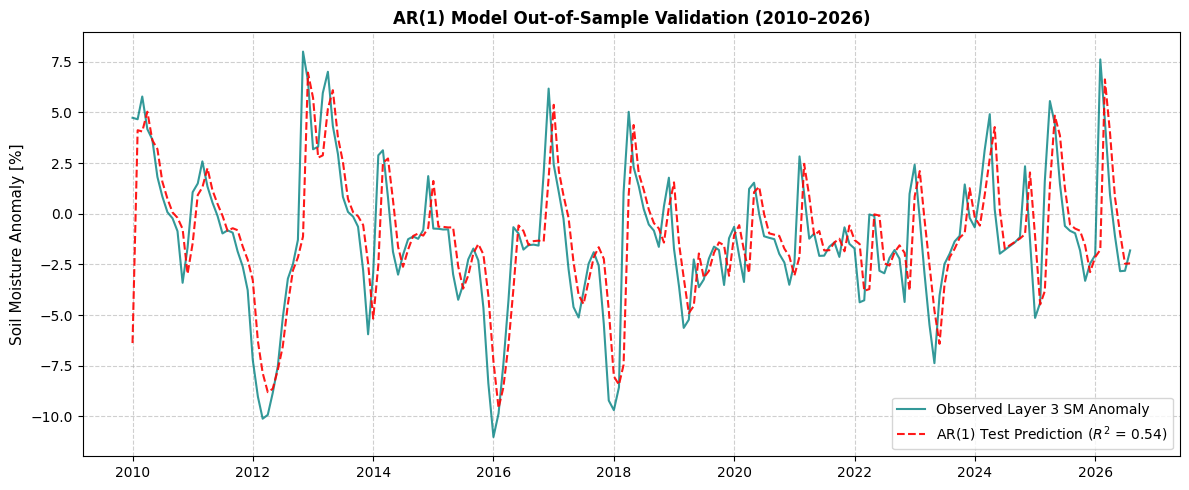

In [ ]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Define folder and file paths
folder = r'C:\MAT3300'
sm_file = os.path.join(folder, 'finalsoildataset.nc') 

ds_sm = xr.open_dataset(sm_file)

sm_time_series = (
    ds_sm["swvl3"]
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
    * 100  
)

df = pd.DataFrame({
    'SM': sm_time_series.values
}, index=sm_time_series.valid_time.values).dropna()

df['month'] = df.index.month

train_mask = df.index.year <= 2010

sm_monthly_means = df.loc[train_mask].groupby('month')['SM'].mean()

df['SM_anomaly'] = df['SM'] - df['month'].map(sm_monthly_means)

df['SM_lag1'] = df['SM_anomaly'].shift(1)
df_model = df.dropna().copy()

train = df_model[df_model.index.year <= 2009]
test = df_model[df_model.index.year >= 2010]

X_train = train[['SM_lag1']]
y_train = train['SM_anomaly']

X_test = test[['SM_lag1']]
y_test = test['SM_anomaly']


reg = LinearRegression(fit_intercept=False).fit(X_train, y_train)

phi = reg.coef_[0]
train_pred = reg.predict(X_train)
test_pred = reg.predict(X_test)

# Metrics
train_r2 = r2_score(y_train, train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))

test_r2 = r2_score(y_test, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

print("--- AR(1) Model Robustness Results ---")
print(f"Soil Memory Coefficient (phi): {phi:.4f}")
print(f"\n[Training Period: 1950–2010]")
print(f"  R²:   {train_r2:.4f}")
print(f"  RMSE: {train_rmse:.4f}%")
print(f"\n[Testing Period: 2010–2026 (Out-of-Sample)]")
print(f"  R²:   {test_r2:.4f}")
print(f"  RMSE: {test_rmse:.4f}%")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(y_test.index, y_test, label="Observed Layer 3 SM Anomaly", color="teal", alpha=0.8)
ax.plot(y_test.index, test_pred, label=f"AR(1) Test Prediction ($R^2$ = {test_r2:.2f})", color="red", linestyle="--", alpha=0.9)

ax.set_ylabel("Soil Moisture Anomaly [%]", fontsize=11)
ax.set_title("AR(1) Model Out-of-Sample Validation (2010–2026)", fontsize=12, fontweight="bold")
ax.legend(frameon=True)
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

folder = r'C:\MAT3300'
sm_file = os.path.join(folder, 'finalsoildataset.nc') 

ds_sm = xr.open_dataset(sm_file)

sm_time_series = (
    ds_sm["swvl3"]
    .sel(valid_time=slice("1950-01-01", "2026-12-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
    * 100  # convert to %
)

df = pd.DataFrame({
    'SM': sm_time_series.values
}, index=sm_time_series.valid_time.values).dropna()

df['month'] = df.index.month
df['SM_anomaly'] = df.groupby('month')['SM'].transform(lambda x: x - x.mean())

df['SM_lag1'] = df['SM_anomaly'].shift(1)
df_model = df.dropna().copy()

X = df_model[['SM_lag1']]
y = df_model['SM_anomaly']

reg = LinearRegression(fit_intercept=False).fit(X, y) # No intercept needed for anomalies
df_model['SM_pred'] = reg.predict(X)

df_model['noise_epsilon'] = y - df_model['SM_pred']

phi = reg.coef_[0]
r2 = reg.score(X, y)
rmse = np.sqrt(np.mean((df_model['noise_epsilon'])**2))

print(f"--- Pure AR(1) Stochastic Soil Model Results ---")
print(f"Soil Memory Coefficient (phi): {phi:.4f}")
print(f"Model R-squared (R²): {r2:.4f}")
print(f"Noise/Shock Standard Deviation: {df_model['noise_epsilon'].std():.4f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(df_model.index, df_model['SM_anomaly'], label="Actual Layer 3 SM Anomaly", color="teal", alpha=0.7)
ax1.plot(df_model.index, df_model['SM_pred'], label=f"AR(1) Memory Model ($R^2$ = {r2:.2f})", color="red", linestyle="--", alpha=0.9)
ax1.set_ylabel("Soil Moisture Anomaly [%]", fontsize=11)
ax1.set_title("Pure Soil Memory Dynamics (Layer 3)", fontsize=12, fontweight="bold")
ax1.legend(frameon=True)
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.bar(df_model.index, df_model['noise_epsilon'], color="sienna", width=25, alpha=0.6, label=r"Irregular Weather Shocks ($\varepsilon_t$)")
ax2.axhline(0, color="black", linestyle="--", alpha=0.5)
ax2.set_ylabel("Shock Magnitude [%]", fontsize=11)
ax2.set_xlabel("Time", fontsize=11)
ax2.set_title("Extracted Irregular Drought/Wet Shocks (Stochastic Noise)", fontsize=12, fontweight="bold")
ax2.legend(frameon=True)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

df_model = df_model.copy()

# Seasonal average for each calendar month
monthly_means = df.groupby('month')['SM'].mean()

# Reconstruct actual soil moisture from mean
df_model['SM_reconstructed'] = (
    df_model['month'].map(monthly_means)
    + df_model['SM_pred']
    + df_model['noise_epsilon']
)
#checks

difference = (
    df_model['SM'] - df_model['SM_reconstructed']
)

print("Maximum reconstruction error:",
      difference.abs().max())

print("Mean reconstruction error:",
      difference.mean())

# convert soil moisture into relative water availability and normalise

SM_min = df_model['SM'].min()
SM_max = df_model['SM'].max()

df_model['W'] = (
    (df_model['SM_reconstructed'] - SM_min)
    / (SM_max - SM_min)
).clip(0, 1)

print(df_model[['SM_reconstructed', 'W']].head())
# Check W values
print(df_model['W'].describe())

print("Minimum W:", df_model['W'].min())
print("Maximum W:", df_model['W'].max())

print("Missing W values:", df_model['W'].isna().sum())


from scipy.interpolate import interp1d

dates = df_model.index
time_days = (dates - dates[0]).days.values.astype(float)

W_values = df_model['W'].values

W_function = interp1d(
    time_days,
    W_values,
    kind='linear',
    bounds_error=False,
    fill_value=(W_values[0], W_values[-1])
)
#error of interpolation-check
W_check = W_function(time_days)

interpolation_error = np.max(
    np.abs(W_check - W_values)
)

print("Maximum interpolation error:", interpolation_error)

In [ ]:
#shallow water formulation

import os
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

folder = r'C:\MAT3300'
file = os.path.join(folder, 'fin.nc')

ds = xr.open_dataset(file)



shallow_sm = (
    (7 * ds["swvl1"] + 21 * ds["swvl2"]) / 28
)

shallow_sm = (
    shallow_sm
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
    * 100
)

# potential evaporation


pev = (
    ds["pev"]
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
)

# 4. Combine into one DataFrame
df = pd.DataFrame({
    "Shallow_SM": shallow_sm.values,
    "PET": pev.values
}, index=pd.to_datetime(shallow_sm["valid_time"].values))

df = df.dropna()
df["month"] = df.index.month

#Calculate monthly anomalies
df["Shallow_anomaly"] = (
    df["Shallow_SM"]
    - df.groupby("month")["Shallow_SM"].transform("mean")
)

df["PET_anomaly"] = (
    df["PET"]
    - df.groupby("month")["PET"].transform("mean")
)

# 6. Create lagged shallow soil-moisture anomaly
df["Shallow_lag1"] = df["Shallow_anomaly"].shift(1)

df_model = df.dropna().copy()


X = df_model[["Shallow_lag1", "PET_anomaly"]]
y = df_model["Shallow_anomaly"]

reg = LinearRegression(fit_intercept=False)
reg.fit(X, y)

# 8. Predictions and residuals
df_model["Shallow_pred"] = reg.predict(X)
df_model["Shallow_noise"] = (
    y - df_model["Shallow_pred"]
)

# 9. Model statistics
phi = reg.coef_[0]
beta = reg.coef_[1]
r2 = r2_score(y, df_model["Shallow_pred"])
rmse = np.sqrt(mean_squared_error(y, df_model["Shallow_pred"]))
residual_sd = df_model["Shallow_noise"].std()

print("----- SHALLOW SOIL MOISTURE ARX MODEL -----")
print(f"Memory coefficient (phi): {phi:.4f}")
print(f"Evaporation coefficient (beta): {beta:.6f}")
print(f"R-squared: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"Residual standard deviation: {residual_sd:.4f}")

# 10. Check model stability
print(f"Stable AR memory (|phi| < 1): {abs(phi) < 1}")
print(f"Expected negative evaporation effect: {beta < 0}")

# 11. Display first observations
print("\nFirst observations:")
print(df_model[
    ["Shallow_SM", "PET", "Shallow_anomaly",
     "PET_anomaly", "Shallow_pred", "Shallow_noise"]
].head())


df["Evap_demand"] = -df["PET"]

periods = {
    "1950-2000": ("1950-01-01", "2000-12-31"),
    "2001-2026": ("2001-01-01", "2026-08-31")
}

results = {}

for name, (start, end) in periods.items():

    data = df.loc[start:end].copy()

    # Calculate monthly anomalies within this period
    data["month"] = data.index.month

    data["Shallow_anomaly"] = (
        data["Shallow_SM"]
        - data.groupby("month")["Shallow_SM"].transform("mean")
    )

    data["Evap_anomaly"] = (
        data["Evap_demand"]
        - data.groupby("month")["Evap_demand"].transform("mean")
    )

    # Create lagged soil-moisture anomaly
    data["Shallow_lag1"] = data["Shallow_anomaly"].shift(1)

    data_model = data.dropna().copy()

    # Fit ARX model without intercept
    X = data_model[["Shallow_lag1", "Evap_anomaly"]]
    y = data_model["Shallow_anomaly"]

    reg = LinearRegression(fit_intercept=False)
    reg.fit(X, y)

    # Predictions and residuals
    data_model["Shallow_pred"] = reg.predict(X)
    data_model["Shallow_noise"] = (
        y - data_model["Shallow_pred"]
    )

    # Store results
    results[name] = {
        "phi": reg.coef_[0],
        "beta": reg.coef_[1],
        "R2": reg.score(X, y),
        "RMSE": np.sqrt(mean_squared_error(
            y, data_model["Shallow_pred"]
        )),
        "residual_sd": data_model["Shallow_noise"].std()
    }

# 4. Display comparison
comparison = pd.DataFrame(results).T

print("\nSHALLOW SOIL MOISTURE ARX MODEL COMPARISON")
print(comparison.round(4))


In [2]:
#shallow water formulation

import os
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

folder = r'C:\MAT3300'
file = os.path.join(folder, 'fin.nc')

ds = xr.open_dataset(file)



shallow_sm = (
    (7 * ds["swvl1"] + 21 * ds["swvl2"]) / 28
)

shallow_sm = (
    shallow_sm
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
    * 100
)

# potential evaporation


pev = (
    ds["pev"]
    .sel(valid_time=slice("1950-01-01", "2026-08-31"))
    .mean(dim=["latitude", "longitude"], skipna=True)
    .resample(valid_time="1MS")
    .mean()
)

# 4. Combine into one DataFrame
df = pd.DataFrame({
    "Shallow_SM": shallow_sm.values,
    "PET": pev.values
}, index=pd.to_datetime(shallow_sm["valid_time"].values))

df = df.dropna()
df["month"] = df.index.month

#Calculate monthly anomalies
df["Shallow_anomaly"] = (
    df["Shallow_SM"]
    - df.groupby("month")["Shallow_SM"].transform("mean")
)

df["PET_anomaly"] = (
    df["PET"]
    - df.groupby("month")["PET"].transform("mean")
)

# 6. Create lagged shallow soil-moisture anomaly
df["Shallow_lag1"] = df["Shallow_anomaly"].shift(1)

df_model = df.dropna().copy()


X = df_model[["Shallow_lag1", "PET_anomaly"]]
y = df_model["Shallow_anomaly"]

reg = LinearRegression(fit_intercept=False)
reg.fit(X, y)

# 8. Predictions and residuals
df_model["Shallow_pred"] = reg.predict(X)
df_model["Shallow_noise"] = (
    y - df_model["Shallow_pred"]
)

# 9. Model statistics
phi = reg.coef_[0]
beta = reg.coef_[1]
r2 = r2_score(y, df_model["Shallow_pred"])
rmse = np.sqrt(mean_squared_error(y, df_model["Shallow_pred"]))
residual_sd = df_model["Shallow_noise"].std()

print("----- SHALLOW SOIL MOISTURE ARX MODEL -----")
print(f"Memory coefficient (phi): {phi:.4f}")
print(f"Evaporation coefficient (beta): {beta:.6f}")
print(f"R-squared: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"Residual standard deviation: {residual_sd:.4f}")

# 10. Check model stability
print(f"Stable AR memory (|phi| < 1): {abs(phi) < 1}")
print(f"Expected negative evaporation effect: {beta < 0}")

# 11. Display first observations
print("\nFirst observations:")
print(df_model[
    ["Shallow_SM", "PET", "Shallow_anomaly",
     "PET_anomaly", "Shallow_pred", "Shallow_noise"]
].head())


df["Evap_demand"] = -df["PET"]

periods = {
    "1950-2000": ("1950-01-01", "2000-12-31"),
    "2001-2026": ("2001-01-01", "2026-08-31")
}

results = {}

for name, (start, end) in periods.items():

    data = df.loc[start:end].copy()

    # Calculate monthly anomalies within this period
    data["month"] = data.index.month

    data["Shallow_anomaly"] = (
        data["Shallow_SM"]
        - data.groupby("month")["Shallow_SM"].transform("mean")
    )

    data["Evap_anomaly"] = (
        data["Evap_demand"]
        - data.groupby("month")["Evap_demand"].transform("mean")
    )

    # Create lagged soil-moisture anomaly
    data["Shallow_lag1"] = data["Shallow_anomaly"].shift(1)

    data_model = data.dropna().copy()

    # Fit ARX model without intercept
    X = data_model[["Shallow_lag1", "Evap_anomaly"]]
    y = data_model["Shallow_anomaly"]

    reg = LinearRegression(fit_intercept=False)
    reg.fit(X, y)

    # Predictions and residuals
    data_model["Shallow_pred"] = reg.predict(X)
    data_model["Shallow_noise"] = (
        y - data_model["Shallow_pred"]
    )

    # Store results
    results[name] = {
        "phi": reg.coef_[0],
        "beta": reg.coef_[1],
        "R2": reg.score(X, y),
        "RMSE": np.sqrt(mean_squared_error(
            y, data_model["Shallow_pred"]
        )),
        "residual_sd": data_model["Shallow_noise"].std()
    }

# 4. Display comparison
comparison = pd.DataFrame(results).T

print("\nSHALLOW SOIL MOISTURE ARX MODEL COMPARISON")
print(comparison.round(4))

shallow_values = df["Shallow_SM"].values
shallow_dates = pd.to_datetime(df.index)

SM_s_min = shallow_values.min()
SM_s_max = shallow_values.max()

W_shallow = (
    (shallow_values - SM_s_min)
    / (SM_s_max - SM_s_min)
)

W_shallow = np.clip(W_shallow, 0, 1)

time_days_shallow = (
    (shallow_dates - shallow_dates[0]).days
).astype(float)

W_shallow_function = interp1d(
    time_days_shallow,
    W_shallow,
    kind="linear",
    bounds_error=False,
    fill_value=(W_shallow[0], W_shallow[-1])
)

W_shallow_reconstructed = W_shallow_function(
    time_days_shallow
)

interpolation_error = np.max(
    np.abs(W_shallow - W_shallow_reconstructed)
)

print("----- SHALLOW WATER INTERPOLATION -----")
print("Minimum W:", W_shallow.min())
print("Maximum W:", W_shallow.max())
print("Mean W:", W_shallow.mean())
print("Number of observations:", len(W_shallow))
print("Maximum interpolation error:", interpolation_error)

daily_days = np.arange(
    time_days_shallow[0],
    time_days_shallow[-1] + 1,
    1
)

W_shallow_daily = W_shallow_function(daily_days)
#checks
print("Daily interpolation minimum:", W_shallow_daily.min())
print("Daily interpolation maximum:", W_shallow_daily.max())
print("Missing daily values:", np.isnan(W_shallow_daily).sum())


----- SHALLOW SOIL MOISTURE ARX MODEL -----
Memory coefficient (phi): 0.4276
Evaporation coefficient (beta): 2511.385986
R-squared: 0.5360
RMSE: 3.0890
Residual standard deviation: 3.0907
Stable AR memory (|phi| < 1): True
Expected negative evaporation effect: False

First observations:
            Shallow_SM       PET  Shallow_anomaly  PET_anomaly  Shallow_pred  \
1950-02-01   32.574368 -0.002237        -1.020031     0.000143     -0.653358   
1950-03-01   26.795864 -0.004013        -4.833248    -0.000099     -0.683916   
1950-04-01   20.318985 -0.006525        -9.178570    -0.001111     -4.857863   
1950-05-01   18.258667 -0.007429        -7.296343    -0.000454     -5.065639   
1950-06-01   15.321827 -0.010007        -5.005152    -0.001134     -5.968532   

            Shallow_noise  
1950-02-01      -0.366673  
1950-03-01      -4.149332  
1950-04-01      -4.320706  
1950-05-01      -2.230703  
1950-06-01       0.963380  

SHALLOW SOIL MOISTURE ARX MODEL COMPARISON
              phi  